# 00 — Document processing

**Objective.** Convert the PDFs of a reproducible MMLongBench-Doc subset into **page records**: one row per physical page, with its native text, OCR text where the page has no text layer, and a rendered image. Retrieval (01), answering (02) and evaluation (03) all start from these records.

| | |
|---|---|
| **Input** | MMLongBench-Doc question table at a pinned revision (tracked in `data/external/mmlongbench_doc/data/`); the 6 sampled PDFs, downloaded at the same revision (git-ignored, CC BY-NC 4.0) |
| **Output** | `data/processed/mmlongbench_doc/questions.parquet`, `pages.parquet`, baseline `render_manifest.csv`, and E1 `render_manifest_e1.csv`; resolution-specific PNG page images in `data/cache/mmlongbench_doc/page_images/` (all git-ignored, regenerable) |
| **Next** | `01_retrieval.ipynb` |

## Method

- **The page is the unit.** The benchmark annotates evidence as page numbers, and the system cites pages, so every representation is stored per physical page.
- **Native text first, OCR as a fallback.** PyMuPDF reads the text objects stored in the PDF. Slide decks exported as images have no text objects, so a page with fewer than `ocr_min_native_words` = 30 native words is rendered at 150 dpi and read with Tesseract (through PyMuPDF, with the project's `resources/tessdata/eng.traineddata`). The threshold is a simple heuristic, not a tuned value. Both texts are kept, so 01 can measure what OCR adds.
- **Page numbering.** Benchmark page $p$ is assumed to be PyMuPDF index $p-1$ (1-based physical pages). This is tested below and again in 01, not assumed.
- **Rendering.** A page of $w \times h$ points rendered with zoom $z$ becomes $zw \times zh$ pixels, i.e. $72z$ dpi. Baseline pages are fitted into a $512 \times 1024$ px box,
  $$z = \min\left(\frac{512}{\min(w, h)},\ \frac{1024}{\max(w, h)}\right).$$
  The box is set by the image-token budget of the answering model (explained in 02). Experiment E1 additionally renders a configurable higher-resolution profile (768 px short side by default) into a separate cache and manifest; it never overwrites the byte-identical baseline.
- **Subset.** Whole documents are sampled with a fixed seed, and every question about them is kept. Questions about the same document share layout and style, so the subset behaves more like 6 units than like 57.

In [1]:
from collections import Counter
from pathlib import Path
import ast
import hashlib
import json
import re
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymupdf
from huggingface_hub import HfApi, hf_hub_download
from IPython.display import Markdown, display

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.width", 160)


def find_project_root(start=Path.cwd()):
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file():
            return candidate
    raise FileNotFoundError("Could not find the repository root")


PROJECT_ROOT = find_project_root()
MMLONG_DIR = PROJECT_ROOT / "data" / "external" / "mmlongbench_doc"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed" / "mmlongbench_doc"
TESSDATA_DIR = PROJECT_ROOT / "resources" / "tessdata"
FROZEN_DIR = PROJECT_ROOT / "experiments" / "frozen" / "mmlongbench_doc"  # saved results, used only as regression references

SETTINGS = {
    "dataset_repo": "yubo2333/MMLongBench-Doc",
    "dataset_revision": "2ff6aa9237fc777b6627dc57a486e9225ac5fb86",  # pins the question table and the PDFs
    "seed": 42,
    "n_documents": 6,
    "max_document_mb": 15.0,
    "ocr_min_native_words": 30,
    "ocr_dpi": 150,
    "render_max_short_side_px": 512,
    "render_max_long_side_px": 1024,
}
RENDER_LABEL = f"short{SETTINGS['render_max_short_side_px']}-long{SETTINGS['render_max_long_side_px']}"
IMAGE_DIR = PROJECT_ROOT / "data" / "cache" / "mmlongbench_doc" / "page_images" / RENDER_LABEL
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

print("Python", sys.version.split()[0], "| PyMuPDF", pymupdf.VersionBind, "| pandas", pd.__version__, "| numpy", np.__version__)

Python 3.12.6 | PyMuPDF 2.1 | pandas 3.1.1 | numpy 2.3.5


## 1. Benchmark questions

The question table is one Parquet file. `evidence_pages` and `evidence_sources` are stored as strings such as `'[5]'`; `ast.literal_eval` parses them without executing code. The table has no question id, so the row position is used (`mmlb-0000`, …). That id is stable **only together with the pinned revision**.

In [2]:
questions_path = hf_hub_download(
    repo_id=SETTINGS["dataset_repo"], repo_type="dataset", revision=SETTINGS["dataset_revision"],
    filename="data/train-00000-of-00001.parquet", local_dir=MMLONG_DIR,
)
raw = pd.read_parquet(questions_path)
raw.insert(0, "qid", [f"mmlb-{index:04d}" for index in raw.index])

bench = raw.copy()
bench["evidence_pages"] = bench["evidence_pages"].map(ast.literal_eval)
bench["evidence_sources"] = bench["evidence_sources"].map(ast.literal_eval)
bench["answerable"] = bench["answer"] != "Not answerable"
bench["n_evidence_pages"] = bench["evidence_pages"].map(len)

assert bench["evidence_pages"].map(lambda pages: all(isinstance(page, int) for page in pages)).all()
assert (bench.loc[~bench["answerable"], "answer_format"] == "None").all()
assert (bench.loc[bench["answerable"], "answer_format"] != "None").all()

print("Shape:", raw.shape, "| first row:", dict(raw.iloc[0][["doc_id", "question", "answer", "evidence_pages", "answer_format"]]))
display(pd.crosstab(bench["answer_format"], bench["answerable"], margins=True))
anomalies = {
    "unanswerable rows that still list evidence pages": int((~bench["answerable"] & (bench["n_evidence_pages"] > 0)).sum()),
    "answerable rows with no evidence page": int((bench["answerable"] & (bench["n_evidence_pages"] == 0)).sum()),
    "rows citing page 0": int(bench["evidence_pages"].map(lambda pages: 0 in pages).sum()),
}
anomalies

Shape: (1091, 8) | first row: {'doc_id': 'PH_2016.06.08_Economy-Final.pdf', 'question': 'According to the report, how do 5% of the Latinos see economic upward mobility for their children?', 'answer': 'Less well-off', 'evidence_pages': '[5]', 'answer_format': 'Str'}


answerable,False,True,All
answer_format,,,
Float,0,160,160
Int,0,290,290
List,0,147,147
None,244,0,244
Str,0,250,250
All,244,847,1091


{'unanswerable rows that still list evidence pages': 7,
 'answerable rows with no evidence page': 9,
 'rows citing page 0': 3}

- **847 answerable and 244 unanswerable questions (22.4 %).** Every unanswerable row has `answer_format == "None"` and no answerable row does. The format column therefore reveals unanswerability, so it must never be shown to a model (02).
- **Annotation anomalies** (7 unanswerable rows with pages, 9 answerable rows without, 3 rows citing page 0) mean that the retrieval population must be defined explicitly (01) rather than read from the column.

## 2. A reproducible document subset

The PDFs on the Hub are listed at the pinned revision **without downloading them**; their sizes bound the download. `sorted(...)` makes the eligible list independent of listing order, and `numpy.random.default_rng(seed)` makes the draw independent of any global random state.

In [3]:
hub_files = HfApi().list_repo_tree(
    SETTINGS["dataset_repo"], path_in_repo="documents", repo_type="dataset", revision=SETTINGS["dataset_revision"]
)
hub_sizes_mb = pd.Series({Path(item.path).name: item.size / 1e6 for item in hub_files if item.path.endswith(".pdf")}, name="size_mb")
referenced = set(bench["doc_id"])
assert referenced <= set(hub_sizes_mb.index), "questions reference PDFs absent from the Hub"

eligible_documents = sorted(doc_id for doc_id in referenced if hub_sizes_mb[doc_id] <= SETTINGS["max_document_mb"])
rng = np.random.default_rng(SETTINGS["seed"])
subset_documents = sorted(rng.choice(eligible_documents, size=SETTINGS["n_documents"], replace=False).tolist())
bench["in_subset"] = bench["doc_id"].isin(subset_documents)
subset = bench[bench["in_subset"]].reset_index(drop=True)

print(f"{len(referenced)} documents referenced, {len(eligible_documents)} of at most {SETTINGS['max_document_mb']:.0f} MB; "
      f"sampled {len(subset_documents)} documents with {len(subset)} questions.")


def percentage_share(series):
    return series.value_counts(normalize=True).mul(100).round(1)


comparison = pd.concat({"full benchmark %": percentage_share(bench["answer_format"]), "subset %": percentage_share(subset["answer_format"])}, axis=1).fillna(0)
comparison.loc["cross-page answerable %"] = [round(100 * ((f["n_evidence_pages"] > 1) & f["answerable"]).mean(), 1) for f in (bench, subset)]
comparison

135 documents referenced, 125 of at most 15 MB; sampled 6 documents with 57 questions.


,full benchmark %,subset %
answer_format,,
Int,26.6,38.6
Str,22.9,14.0
None,22.4,29.8
Float,14.7,12.3
List,13.5,5.3
cross-page answerable %,33.0,31.6


In [4]:
pdf_paths = {
    doc_id: Path(hf_hub_download(repo_id=SETTINGS["dataset_repo"], repo_type="dataset", revision=SETTINGS["dataset_revision"],
                                 filename=f"documents/{doc_id}", local_dir=MMLONG_DIR))
    for doc_id in subset_documents
}
page_counts = {}
for doc_id, path in pdf_paths.items():
    with pymupdf.open(path) as pdf:
        page_counts[doc_id] = pdf.page_count

subset["page_count"] = subset["doc_id"].map(page_counts)
out_of_range = subset[subset["evidence_pages"].map(lambda pages: max(pages, default=0)) > subset["page_count"]]
assert out_of_range.empty, out_of_range[["qid", "evidence_pages", "page_count"]]

document_table = subset.groupby("doc_id").agg(
    doc_type=("doc_type", "first"), questions=("qid", "size"), unanswerable=("answerable", lambda a: int((~a).sum()))
)
document_table["size_mb"] = hub_sizes_mb.reindex(document_table.index).round(2)
document_table["pages"] = document_table.index.map(page_counts)
document_table

,doc_type,questions,unanswerable,size_mb,pages
doc_id,,,,,
2210.02442v1.pdf,Academic paper,9,3,4.70,24
PG_2020.05.21_International-Cooperation-COVID_FINAL.pdf,Research report / Introduction,11,4,3.30,26
bdf54dxa.pdf,Guidebook,7,2,7.67,54
earlybird-110722143746-phpapp02_95.pdf,Research report / Introduction,9,2,4.04,41
germanwingsdigitalcrisisanalysis-150403064828-conversion-gate01_95.pdf,Research report / Introduction,16,5,1.46,23
watch_d.pdf,Guidebook,5,1,0.39,27


The subset over-represents `Int` answers and unanswerable questions compared with the full benchmark, and the size filter excludes the largest (possibly hardest) PDFs. Numbers in later notebooks describe this subset only.

## 3. Page anatomy: which pages carry a text layer?

Before extracting anything, a few observable features per page show which pages need OCR (the routing idea of the archived notebooks 02–03): the number of native words, the number of placed raster images, the share of the page covered by the largest image, and the number of vector drawing paths.

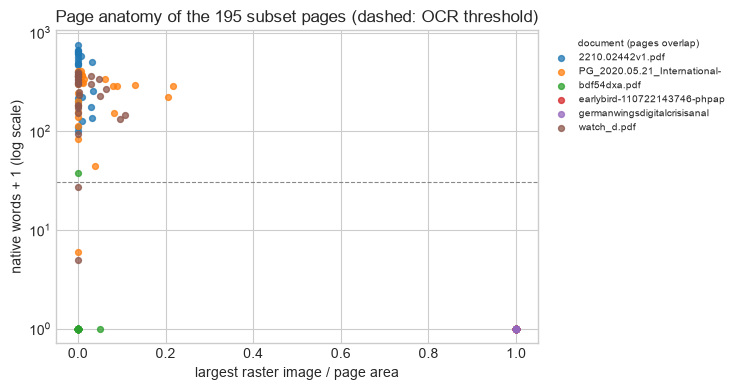

,pages,under_30_native_words,full_page_image,no_raster_image,median_vector_drawings
doc_id,,,,,
2210.02442v1.pdf,24,0,0,17,18.0
PG_2020.05.21_International-Cooperation-COVID_FINAL.pdf,26,1,0,11,6.5
bdf54dxa.pdf,54,53,0,52,1123.5
earlybird-110722143746-phpapp02_95.pdf,41,41,41,0,0.0
germanwingsdigitalcrisisanalysis-150403064828-conversion-gate01_95.pdf,23,23,23,0,0.0
watch_d.pdf,27,2,0,15,2.0


In [5]:
def page_features(page):
    images = page.get_image_info()
    page_area = page.rect.get_area()
    coverage = max(((pymupdf.Rect(image["bbox"]) & page.rect).get_area() / page_area for image in images), default=0.0)
    native_words = len(page.get_text("text", sort=True).split())  # same count as the extraction rule below
    return {"native_words": native_words, "image_count": len(images), "largest_image_fraction": round(coverage, 3),
            "vector_drawings": len(page.get_drawings())}


feature_rows = []
for doc_id, path in pdf_paths.items():
    with pymupdf.open(path) as pdf:
        for index, page in enumerate(pdf):
            feature_rows.append({"doc_id": doc_id, "page": index + 1, **page_features(page)})
features = pd.DataFrame(feature_rows)

fig, ax = plt.subplots(figsize=(7.5, 4))
for doc_id, group in features.groupby("doc_id"):
    ax.scatter(group["largest_image_fraction"], group["native_words"] + 1, s=18, alpha=0.75, label=doc_id[:28])
ax.axhline(SETTINGS["ocr_min_native_words"] + 1, color="#888888", linestyle="--", linewidth=0.8)
ax.set(xlabel="largest raster image / page area", ylabel="native words + 1 (log scale)", yscale="log",
       title=f"Page anatomy of the {len(features)} subset pages (dashed: OCR threshold)")
ax.legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.01, 1), title="document (pages overlap)", title_fontsize=7)
plt.tight_layout()
plt.show()

features.groupby("doc_id").agg(
    pages=("page", "size"),
    under_30_native_words=("native_words", lambda w: int((w < 30).sum())),
    full_page_image=("largest_image_fraction", lambda f: int((f >= 0.9).sum())),
    no_raster_image=("image_count", lambda c: int((c == 0).sum())),
    median_vector_drawings=("vector_drawings", "median"),
)

- **Two slide decks** (`earlybird`, `germanwings`, 64 pages, overlapping at the bottom right) are exported as images: every page is one full-page raster image with no text layer.
- **`bdf54dxa` has neither a text layer nor a raster image** (bottom left): 52 of its 54 pages hold only vector drawings, a median of over 1,000 per page. Its text was converted to **outlines**: it looks like text but is drawn as shapes, so PyMuPDF has nothing to read. It is not a scan, although OCR treats it the same way.
- The other three documents are born-digital, with hundreds of native words per page.

In all three cases without a text layer, a text pipeline sees **empty pages** unless OCR runs.

## 4. Text extraction with an OCR fallback

First the operation on one page: the evidence page of the first answerable single-page question (chosen by rule).

**mmlb-0033** · `earlybird-110722143746-phpapp02_95.pdf` p.6 · **Q:** How many more millions of dollars was the median exit valuation in the USA compared to Europe at the time of the presentation? · **reference:** 63

native words: 0 | OCR words: 86
At the same time,e real performanceGg shows
European VCa | drivingee the best exito multiplese
globally


 Exits over $ 100M
 2005 - Q1/2011





 7.2

 Median Multiple
 of Cash Invested 45
 Median Multiple
 of Cash Invested

 Proportionally Europe
 is producing higher exit
 multiples and, although
 average exit values are
 ca. 25% smaller, lower
 entry valuations and ;
 higher capital efficiency Europe USA
 overcompensate for
 disadvantages in exit .
 value. Number a) 596.
 Median Exit Valuation ___ S173 $236M
 % with Multiple of Cash=5 57.26% . 41.27% .


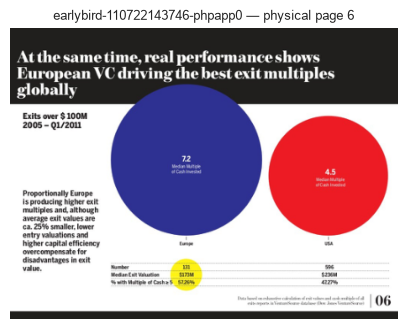

In [6]:
assert (TESSDATA_DIR / "eng.traineddata").is_file(), "OCR model missing: resources/tessdata/eng.traineddata"

example = subset[subset["answerable"] & (subset["n_evidence_pages"] == 1)].iloc[0]
example_page = example["evidence_pages"][0]
with pymupdf.open(pdf_paths[example["doc_id"]]) as pdf:
    page = pdf[example_page - 1]  # benchmark page p (1-based) -> PyMuPDF index p - 1
    native_text = page.get_text("text", sort=True)
    # `page` must stay referenced while its OCR text page is read: PyMuPDF keeps only a weak reference.
    ocr_textpage = page.get_textpage_ocr(language="eng", dpi=SETTINGS["ocr_dpi"], full=True, tessdata=str(TESSDATA_DIR))
    ocr_text = page.get_text("text", textpage=ocr_textpage, sort=True)
    pixmap = page.get_pixmap(matrix=pymupdf.Matrix(0.6, 0.6), alpha=False)

display(Markdown(f"**{example['qid']}** · `{example['doc_id']}` p.{example_page} · **Q:** {example['question']} · **reference:** {example['answer']}"))
print(f"native words: {len(native_text.split())} | OCR words: {len(ocr_text.split())}")
print(re.sub(r"[ \t]+", " ", ocr_text)[:600])
fig, ax = plt.subplots(figsize=(5, 4))
ax.imshow(np.frombuffer(pixmap.samples, dtype=np.uint8).reshape(pixmap.height, pixmap.width, pixmap.n))
ax.set_title(f"{example['doc_id'][:30]} — physical page {example_page}", fontsize=9)
ax.axis("off")
plt.show()

The page has no text layer. OCR makes it searchable but noisy: `exito multiplese`, the bubble value `4.5` becomes `45`, and the layout (which number belongs to which bubble) is lost. The reference answer `63` is not written anywhere: it is $236 - 173$, two values from the small table under the chart.

Now the same rule for every page of the subset. Both texts are kept.

In [7]:
page_rows = []
started = time.perf_counter()
for doc_id, path in pdf_paths.items():
    with pymupdf.open(path) as pdf:
        for index, page in enumerate(pdf):
            native_text = page.get_text("text", sort=True)
            native_words = len(native_text.split())
            ocr_used = native_words < SETTINGS["ocr_min_native_words"]
            if ocr_used:
                ocr_textpage = page.get_textpage_ocr(language="eng", dpi=SETTINGS["ocr_dpi"], full=True, tessdata=str(TESSDATA_DIR))
                text = page.get_text("text", textpage=ocr_textpage, sort=True)
            else:
                text = native_text
            page_rows.append({
                "doc_id": doc_id,
                "page": index + 1,  # 1-based physical page number
                "native_text": native_text,
                "native_words": native_words,
                "ocr_used": ocr_used,
                "text": text,  # native text, or OCR text below the threshold: the text the pipeline uses
                "words": len(text.split()),
                "width_pt": page.rect.width,
                "height_pt": page.rect.height,
                "rotation": page.rotation,
                "cropbox_is_mediabox": page.cropbox == page.mediabox,
            })
pages = pd.DataFrame(page_rows).merge(features, on=["doc_id", "page"], how="left", validate="one_to_one", suffixes=("", "_feature"))
assert (pages["native_words"] == pages.pop("native_words_feature")).all()
print(f"Extracted {len(pages)} pages in {time.perf_counter() - started:.0f} s; OCR on {int(pages['ocr_used'].sum())} pages.")

pages.groupby("doc_id").agg(
    pages=("page", "size"),
    page_size_pt=("width_pt", lambda w: f"{w.iloc[0]:.0f} × {pages.loc[w.index[0], 'height_pt']:.0f}"),
    median_native_words=("native_words", "median"),
    pages_ocr=("ocr_used", "sum"),
    median_words_used=("words", "median"),
    rotated=("rotation", lambda r: int((r != 0).sum())),
    cropbox_differs=("cropbox_is_mediabox", lambda same: int((~same).sum())),
)

Image too small to scale!! (2x36 vs min width of 3)
Line cannot be recognized!!


Extracted 195 pages in 39 s; OCR on 120 pages.


,pages,page_size_pt,median_native_words,pages_ocr,median_words_used,rotated,cropbox_differs
doc_id,,,,,,,
2210.02442v1.pdf,24,612 × 792,473.0,0,473.0,0,0
PG_2020.05.21_International-Cooperation-COVID_FINAL.pdf,26,612 × 792,289.0,1,289.0,0,0
bdf54dxa.pdf,54,612 × 792,0.0,53,158.0,0,0
earlybird-110722143746-phpapp02_95.pdf,41,768 × 576,0.0,41,45.0,0,0
germanwingsdigitalcrisisanalysis-150403064828-conversion-gate01_95.pdf,23,768 × 432,0.0,23,81.0,0,0
watch_d.pdf,27,595 × 842,300.0,2,300.0,0,0


- **120 of 195 pages needed OCR**, almost all in the three documents without a text layer (117 of their 118 pages). Without OCR, both a text retriever and a text-only model would see empty pages; 01 measures the consequence.
- No page is rotated and no crop box differs from the media box, so rendering the crop box with the page's own rotation shows exactly the visible page.

## 5. Page-number convention

**Hypothesis:** benchmark page $p$ = PyMuPDF index $p-1$. Three independent checks:

1. **Answer strings.** For answerable questions with a distinctive short answer (≥ 3 characters, not a list), search the answer as a whole token sequence in the text of each evidence page under three alignments ($p-1$, $p$, $p+1$). Answers that live only in figures are not found under any alignment; that shrinks the sample without favouring a hypothesis.
2. **Known-answer rendering test.** A synthetic PDF with pages labelled `PAGE 1–3`; rendering page $k$ and reading it with OCR must give `PAGE k`. Plain indexing `pdf[p - 1]` silently returns the **last** page for $p = 0$, so a guarded accessor `pdf_page` is used everywhere pages are rendered.
3. **Real pages.** OCR of `pdf_page(p)` at 150 dpi must match the native text of page $p$ better than that of $p \pm 1$.

A fourth check, using the retriever's top-ranked page, is in 01.

In [8]:
def normalize_text(text):
    return re.sub(r"\s+", " ", str(text).lower()).strip()


def answer_pattern(answer):
    # Whole-token match: the answer "12" must not match inside "2012".
    return re.compile(r"(?<![0-9a-z])" + re.escape(normalize_text(answer)) + r"(?![0-9a-z])")


normalized_pages = {(row.doc_id, row.page): normalize_text(row.text) for row in pages.itertuples()}
alignments = {"page p - 1": -1, "page p (1-based)": 0, "page p + 1 (0-based)": 1}
probe = subset[subset["answerable"] & (subset["answer_format"] != "List") & (subset["answer"].str.len() >= 3)]
alignment = pd.DataFrame([
    {
        **{label: any(answer_pattern(row.answer).search(normalized_pages.get((row.doc_id, page + offset), "")) for page in row.evidence_pages)
           for label, offset in alignments.items()},
        "anywhere in the document": any(answer_pattern(row.answer).search(text) for (doc_id, _), text in normalized_pages.items() if doc_id == row.doc_id),
    }
    for row in probe.itertuples()
])
found = alignment.sum()
assert found["page p (1-based)"] > max(found["page p - 1"], found["page p + 1 (0-based)"])
found.rename(f"probe questions where the answer string is found (of {len(alignment)})").to_frame()

,probe questions where the answer string is found (of 17)
page p - 1,3
page p (1-based),6
page p + 1 (0-based),3
anywhere in the document,9


In [9]:
def pdf_page(pdf, page_number):
    # 1-based physical page number -> PyMuPDF page. Rejects 0 and out-of-range numbers:
    # pdf[-1] is valid Python and silently returns the LAST page.
    if not isinstance(page_number, (int, np.integer)) or not 1 <= page_number <= pdf.page_count:
        raise IndexError(f"page {page_number!r} is not a 1-based page number of a {pdf.page_count}-page PDF")
    return pdf[int(page_number) - 1]


def render_zoom(width_pt, height_pt):
    return min(SETTINGS["render_max_short_side_px"] / min(width_pt, height_pt), SETTINGS["render_max_long_side_px"] / max(width_pt, height_pt))


def render_png(page):
    # Whole page (crop box, page rotation applied), opaque RGB, fitted in the render box.
    zoom = render_zoom(page.rect.width, page.rect.height)
    return page.get_pixmap(matrix=pymupdf.Matrix(zoom, zoom), alpha=False).tobytes("png"), zoom


def ocr_png(png):
    # Tesseract OCR of a PNG through PyMuPDF: same engine and model as the text extraction.
    with pymupdf.open("pdf", pymupdf.Pixmap(png).pdfocr_tobytes(language="eng", tessdata=str(TESSDATA_DIR))) as ocr_pdf:
        return ocr_pdf[0].get_text()


synthetic = pymupdf.open()
for number in (1, 2, 3):
    synthetic.new_page(width=612, height=792).insert_text((72, 300), f"PAGE {number}", fontsize=96)
synthetic_reads = {number: normalize_text(ocr_png(render_png(pdf_page(synthetic, number))[0])) for number in (1, 2, 3)}
assert synthetic_reads == {1: "page 1", 2: "page 2", 3: "page 3"}, synthetic_reads
print("Synthetic known-answer test:", synthetic_reads)
print("synthetic[0 - 1] silently returns:", repr(synthetic[0 - 1].get_text().strip()), "— the last page, no error")
try:
    pdf_page(synthetic, 0)
    raise AssertionError("page 0 was accepted")
except IndexError as error:
    print("pdf_page(synthetic, 0) raises IndexError:", error)
synthetic.close()

Synthetic known-answer test: {1: 'page 1', 2: 'page 2', 3: 'page 3'}
synthetic[0 - 1] silently returns: 'PAGE 3' — the last page, no error
pdf_page(synthetic, 0) raises IndexError: page 0 is not a 1-based page number of a 3-page PDF


In [10]:
WORD_PATTERN = re.compile(r"[a-z]{4,}")  # words of 4+ letters: distinctive, robust to OCR punctuation noise


def recovered_fraction(ocr_text, reference_text):
    reference_words = set(WORD_PATTERN.findall(str(reference_text).lower()))
    return len(set(WORD_PATTERN.findall(ocr_text.lower())) & reference_words) / len(reference_words) if reference_words else np.nan


native_lookup = pages.set_index(["doc_id", "page"])["native_text"]
mapping_rows = []
for doc_id, group in pages[~pages["ocr_used"]].groupby("doc_id"):
    for page_number in group["page"].iloc[np.unique(np.linspace(0, len(group) - 1, 3).round().astype(int))]:
        with pymupdf.open(pdf_paths[doc_id]) as pdf:
            ocr_150 = ocr_png(pdf_page(pdf, int(page_number)).get_pixmap(dpi=150, alpha=False).tobytes("png"))
        mapping_rows.append({"doc_id": doc_id[:28], "page": page_number, **{
            f"vs native p{offset:+d}" if offset else "vs native p": recovered_fraction(ocr_150, native_lookup.get((doc_id, page_number + offset), ""))
            for offset in (-1, 0, 1)}})
mapping = pd.DataFrame(mapping_rows)
neighbours = mapping[["vs native p-1", "vs native p+1"]].max(axis=1).fillna(0)
# The comparison is informative only where OCR can read the page itself (>= half of its own native words).
mapping["informative"] = mapping["vs native p"] >= 0.5
assert (mapping.loc[mapping["informative"], "vs native p"] > neighbours[mapping["informative"]]).all(), "pdf_page(p) matches a neighbour better"
print(f"Real-page mapping: on all {int(mapping['informative'].sum())} informative pages of {len(mapping)} sampled, "
      "OCR of pdf_page(p) matches page p best.")
mapping.round(2)

Real-page mapping: on all 9 informative pages of 10 sampled, OCR of pdf_page(p) matches page p best.


,doc_id,page,vs native p-1,vs native p,vs native p+1,informative
0,2210.02442v1.pdf,1,NaN,0.95,0.29,True
1,2210.02442v1.pdf,13,0.07,0.99,0.14,True
2,2210.02442v1.pdf,24,0.14,0.90,NaN,True
3,PG_2020.05.21_International-,1,NaN,0.45,0.67,False
4,PG_2020.05.21_International-,14,0.45,1.00,0.76,True
5,PG_2020.05.21_International-,26,0.10,1.00,NaN,True
6,bdf54dxa.pdf,54,NaN,1.00,NaN,True
7,watch_d.pdf,2,0.33,0.94,0.26,True
8,watch_d.pdf,14,0.23,0.99,0.42,True
9,watch_d.pdf,27,0.16,0.97,NaN,True


The 1-based convention wins every check: answer strings are found most often on page $p$ (weak evidence on its own, because few short answers occur verbatim and OCR is noisy), the synthetic pages read back exactly, and every informative real page matches its own native text best, by a wide margin (0.90–1.00 against at most 0.76 for a neighbour). One sampled page is **uninformative**: on the PG report's cover (p.1), OCR at 150 dpi recovers only 45 % of the page's own native words, so the comparison with its neighbours says nothing about the mapping. A first version of this check, without the precondition, failed on that page. The `pdf[-1]` trap is the silent failure the guard prevents.

## 6. Render page images

The operation once, on the example page, then for every page. Images are cached as PNG (lossless: no JPEG artefacts around thin lines and small digits) under a folder named after the render box, so caches made with different settings never mix.

In [11]:
with pymupdf.open(pdf_paths[example["doc_id"]]) as pdf:
    page = pdf_page(pdf, example_page)
    zoom = render_zoom(page.rect.width, page.rect.height)
    example_png = page.get_pixmap(matrix=pymupdf.Matrix(zoom, zoom), alpha=False).tobytes("png")
    width_pt, height_pt = page.rect.width, page.rect.height  # read before the PDF closes
example_size = (round(width_pt * zoom), round(height_pt * zoom))
print(f"{example['doc_id'][:30]} p.{example_page}: {width_pt:.0f} × {height_pt:.0f} pt, zoom {zoom:.4f} "
      f"({72 * zoom:.1f} dpi) -> {example_size[0]} × {example_size[1]} px, PNG {len(example_png) / 1024:.1f} KB")


def image_path(doc_id, page_number):
    return IMAGE_DIR / Path(doc_id).stem / f"page_{page_number:03d}.png"


manifest_rows = []
started = time.perf_counter()
for doc_id, path in pdf_paths.items():
    with pymupdf.open(path) as pdf:
        for page_number in range(1, pdf.page_count + 1):
            png, zoom = render_png(pdf_page(pdf, page_number))
            target = image_path(doc_id, page_number)
            target.parent.mkdir(parents=True, exist_ok=True)
            target.write_bytes(png)
            pixmap = pymupdf.Pixmap(png)
            manifest_rows.append({
                "doc_id": doc_id, "page": page_number, "width_px": pixmap.width, "height_px": pixmap.height,
                "zoom": round(zoom, 5), "effective_dpi": round(72 * zoom, 1), "png_kb": round(len(png) / 1024, 1),
                "sha256": hashlib.sha256(png).hexdigest(), "image_path": str(target.relative_to(PROJECT_ROOT)),
            })
manifest = pd.DataFrame(manifest_rows)
example_row = manifest[(manifest["doc_id"] == example["doc_id"]) & (manifest["page"] == example_page)]
assert example_row["sha256"].item() == hashlib.sha256(example_png).hexdigest()  # the loop reproduces the step-by-step render
print(f"Rendered {len(manifest)} pages in {time.perf_counter() - started:.1f} s; {manifest['png_kb'].sum() / 1024:.1f} MB of PNG.")
manifest.groupby("doc_id").agg(image_px=("width_px", lambda w: f"{w.iloc[0]} × {manifest.loc[w.index[0], 'height_px']}"),
                               effective_dpi=("effective_dpi", "first"), median_png_kb=("png_kb", "median"))

earlybird-110722143746-phpapp0 p.6: 768 × 576 pt, zoom 0.8889 (64.0 dpi) -> 683 × 512 px, PNG 176.5 KB


Rendered 195 pages in 5.1 s; 24.2 MB of PNG.


,image_px,effective_dpi,median_png_kb
doc_id,,,
2210.02442v1.pdf,512 × 663,60.2,88.25
PG_2020.05.21_International-Cooperation-COVID_FINAL.pdf,512 × 663,60.2,71.20
bdf54dxa.pdf,512 × 663,60.2,46.30
earlybird-110722143746-phpapp02_95.pdf,683 × 512,64.0,200.20
germanwingsdigitalcrisisanalysis-150403064828-conversion-gate01_95.pdf,911 × 512,85.3,226.10
watch_d.pdf,512 × 725,61.9,68.80


In [12]:
# Fit inside the box, aspect ratio kept within 1 px (no crop, no stretch), and deterministic rendering.
box_short, box_long = SETTINGS["render_max_short_side_px"], SETTINGS["render_max_long_side_px"]
sizes = manifest.merge(pages[["doc_id", "page", "width_pt", "height_pt"]], on=["doc_id", "page"])
assert (sizes[["width_px", "height_px"]].min(axis=1) <= box_short).all() and (sizes[["width_px", "height_px"]].max(axis=1) <= box_long).all()
assert ((sizes["width_px"] - sizes["width_pt"] * sizes["zoom"]).abs() <= 1).all()
assert ((sizes["height_px"] - sizes["height_pt"] * sizes["zoom"]).abs() <= 1).all()
for row in manifest.iloc[:: len(manifest) // 6].itertuples():
    with pymupdf.open(pdf_paths[row.doc_id]) as pdf:
        assert hashlib.sha256(render_png(pdf_page(pdf, row.page))[0]).hexdigest() == row.sha256

# Regression: the images sent to the model in the frozen image run are reproduced byte for byte.
frozen_manifest = pd.read_csv(next(FROZEN_DIR.glob("image_run_*")) / "render_manifest.csv")
merged = frozen_manifest.merge(manifest, on=["doc_id", "page"], suffixes=("_frozen", ""), validate="one_to_one")
assert len(merged) == len(frozen_manifest) and (merged["sha256_frozen"] == merged["sha256"]).all()
print(f"All {len(merged)} page images used by the frozen image run are byte-identical to this rendering.")

All 124 page images used by the frozen image run are byte-identical to this rendering.


Each document has one page shape and therefore one image size: letter pages become 512 × 663 px (≈ 60 dpi), A4 pages 512 × 725, 4:3 slides 683 × 512 and 16:9 slides 911 × 512. The SHA-256 stored per page identifies exactly which pixels a request contained, and the 124 pages the frozen image run sent are reproduced byte for byte.

## 7. Save the page records

In [13]:
question_columns = ["qid", "doc_id", "doc_type", "question", "answer", "answer_format", "evidence_pages", "evidence_sources",
                    "answerable", "n_evidence_pages", "in_subset"]
bench[question_columns].to_parquet(PROCESSED_DIR / "questions.parquet", index=False)
pages.to_parquet(PROCESSED_DIR / "pages.parquet", index=False)
manifest.to_csv(PROCESSED_DIR / "render_manifest.csv", index=False)

saved = pd.read_parquet(PROCESSED_DIR / "pages.parquet")
print("pages.parquet schema:")
display(pd.DataFrame({"dtype": saved.dtypes.astype(str), "example (first page)": saved.iloc[0].map(lambda v: " ".join(str(v).split())[:60])}))
pd.DataFrame([{"file": p.name, "KB": round(p.stat().st_size / 1024, 1)} for p in sorted(PROCESSED_DIR.glob("*.*"))])

pages.parquet schema:


,dtype,example (first page)
doc_id,str,2210.02442v1.pdf
page,int64,1
native_text,str,Making Your First Choice: To Address Cold Start Problem in V
native_words,int64,485
ocr_used,bool,False
text,str,Making Your First Choice: To Address Cold Start Problem in V
words,int64,485
width_pt,float64,612.0
height_pt,float64,792.0
rotation,int64,0


,file,KB
0,evaluation_summary.json,23.4
1,pages.parquet,233.7
2,questions.parquet,88.3
3,rankings.parquet,6.1
4,render_manifest.csv,42.4
5,render_manifest_e1.csv,44.9
6,retrieval_per_question.csv,16.6
7,retrieval_summary.csv,0.2


## 8. E1: render a separate higher-resolution profile

E1 changes only raster resolution. Its version-controlled specification fixes the treatment at a `768 × 1536` box, preserving aspect ratio, page boundaries, crop box, rotation, RGB conversion and PNG encoding from the baseline. GPT-4o-mini's documented high-detail billing path reduces a shortest side above 768 px to 768, so a larger render would be a separate diagnostic rather than an E1 treatment. The profile name is part of every path, so the 512-px baseline cannot be overwritten.

In [14]:
E1_SHORT_SIDE_PX = 768  # frozen by experiments/specs/e1_image_resolution_v1.json
E1_LONG_SIDE_PX = 2 * E1_SHORT_SIDE_PX
E1_RENDER_LABEL = f"short{E1_SHORT_SIDE_PX}-long{E1_LONG_SIDE_PX}"
E1_IMAGE_DIR = PROJECT_ROOT / "data" / "cache" / "mmlongbench_doc" / "page_images" / E1_RENDER_LABEL


def validate_e1_resolution(short_side_px, long_side_px):
    if short_side_px <= SETTINGS["render_max_short_side_px"]:
        raise ValueError("E1 short side must exceed the 512-px baseline")
    if long_side_px < short_side_px:
        raise ValueError("render box long side must be at least its short side")


try:
    validate_e1_resolution(400, 800)
    raise AssertionError("an E1 profile below the baseline was accepted")
except ValueError:
    pass
validate_e1_resolution(E1_SHORT_SIDE_PX, E1_LONG_SIDE_PX)


def render_png_profile(page, short_side_px, long_side_px):
    zoom = min(short_side_px / min(page.rect.width, page.rect.height),
               long_side_px / max(page.rect.width, page.rect.height))
    png = page.get_pixmap(matrix=pymupdf.Matrix(zoom, zoom), alpha=False).tobytes("png")
    return png, zoom


e1_manifest_rows = []
started = time.perf_counter()
for doc_id, path in pdf_paths.items():
    with pymupdf.open(path) as pdf:
        for page_number in range(1, pdf.page_count + 1):
            png, zoom = render_png_profile(pdf_page(pdf, page_number), E1_SHORT_SIDE_PX, E1_LONG_SIDE_PX)
            target = E1_IMAGE_DIR / Path(doc_id).stem / f"page_{page_number:03d}.png"
            target.parent.mkdir(parents=True, exist_ok=True)
            target.write_bytes(png)
            pixmap = pymupdf.Pixmap(png)
            e1_manifest_rows.append({
                "doc_id": doc_id, "page": page_number, "render_profile": "e1",
                "render_max_short_side_px": E1_SHORT_SIDE_PX, "render_max_long_side_px": E1_LONG_SIDE_PX,
                "width_px": pixmap.width, "height_px": pixmap.height, "zoom": round(zoom, 5),
                "effective_dpi": round(72 * zoom, 1), "png_kb": round(len(png) / 1024, 1),
                "sha256": hashlib.sha256(png).hexdigest(), "image_path": str(target.relative_to(PROJECT_ROOT)),
            })
e1_manifest = pd.DataFrame(e1_manifest_rows)
e1_manifest.to_csv(PROCESSED_DIR / "render_manifest_e1.csv", index=False)

e1_sizes = e1_manifest.merge(pages[["doc_id", "page", "width_pt", "height_pt"]], on=["doc_id", "page"], validate="one_to_one")
assert len(e1_manifest) == len(manifest) and e1_manifest[["doc_id", "page"]].equals(manifest[["doc_id", "page"]])
assert (e1_sizes[["width_px", "height_px"]].min(axis=1) <= E1_SHORT_SIDE_PX).all()
assert (e1_sizes[["width_px", "height_px"]].max(axis=1) <= E1_LONG_SIDE_PX).all()
assert ((e1_sizes["width_px"] - e1_sizes["width_pt"] * e1_sizes["zoom"]).abs() <= 1).all()
assert ((e1_sizes["height_px"] - e1_sizes["height_pt"] * e1_sizes["zoom"]).abs() <= 1).all()
assert (e1_manifest["sha256"].to_numpy() != manifest["sha256"].to_numpy()).all(), "E1 unexpectedly reproduced baseline pixels"
print(f"Rendered E1 profile {E1_RENDER_LABEL}: {len(e1_manifest)} pages in {time.perf_counter() - started:.1f} s; "
      f"{e1_manifest['png_kb'].sum() / 1024:.1f} MB, separate from {RENDER_LABEL}.")
e1_manifest.groupby("doc_id").agg(image_px=("width_px", lambda w: f"{w.iloc[0]} × {e1_manifest.loc[w.index[0], 'height_px']}"),
                                        effective_dpi=("effective_dpi", "first"), median_png_kb=("png_kb", "median"))

Rendered E1 profile short768-long1536: 195 pages in 7.8 s; 46.8 MB, separate from short512-long1024.


,image_px,effective_dpi,median_png_kb
doc_id,,,
2210.02442v1.pdf,768 × 994,90.4,170.45
PG_2020.05.21_International-Cooperation-COVID_FINAL.pdf,768 × 994,90.4,141.35
bdf54dxa.pdf,768 × 994,90.4,82.80
earlybird-110722143746-phpapp02_95.pdf,1024 × 768,96.0,382.00
germanwingsdigitalcrisisanalysis-150403064828-conversion-gate01_95.pdf,1366 × 768,128.0,482.40
watch_d.pdf,768 × 1087,92.9,131.50


## Validation

In [15]:
# 1. The subset is a pure function of the seed and the eligible list, and equals the frozen runs' subset.
assert sorted(np.random.default_rng(SETTINGS["seed"]).choice(eligible_documents, size=SETTINGS["n_documents"], replace=False).tolist()) == subset_documents
frozen_settings = json.loads((next(FROZEN_DIR.glob("text_run_*")) / "settings.json").read_text())
assert frozen_settings["subset_documents"] == subset_documents and frozen_settings["subset_qids"] == subset["qid"].tolist()

# 2. One record per physical page, numbered 1..n in every document, with a cached image.
assert all(sorted(group["page"]) == list(range(1, page_counts[doc_id] + 1)) for doc_id, group in pages.groupby("doc_id"))
assert len(manifest) == len(pages) and all((PROJECT_ROOT / path).is_file() for path in manifest["image_path"])
assert len(e1_manifest) == len(pages) and all((PROJECT_ROOT / path).is_file() for path in e1_manifest["image_path"])
assert set(manifest["image_path"]).isdisjoint(set(e1_manifest["image_path"])), "E1 may not overwrite baseline images"

# 3. The OCR rule is applied exactly: OCR iff fewer native words than the threshold; the text used is never empty after OCR on these pages.
assert (pages["ocr_used"] == (pages["native_words"] < SETTINGS["ocr_min_native_words"])).all()
assert (pages.loc[~pages["ocr_used"], "text"] == pages.loc[~pages["ocr_used"], "native_text"]).all()
assert not ((pages["native_words"] >= SETTINGS["ocr_min_native_words"]) & (pages["largest_image_fraction"] >= 0.9)).any(), "a hybrid page needs routing"

# 4. Saved files round-trip with list columns intact.
reloaded = pd.read_parquet(PROCESSED_DIR / "questions.parquet")
assert reloaded["in_subset"].sum() == len(subset) and list(reloaded.loc[reloaded["qid"] == example["qid"], "evidence_pages"].item()) == [example_page]
print("All validation checks passed.")

All validation checks passed.


## Interpretation

- **Half of the sampled documents have no text layer**: two slide decks exported as images, and one guidebook whose text is vector outlines. OCR turns 120 empty pages into searchable but noisy text. This is the failure of a text pipeline on image-like pages, observed at benchmark scale.
- **OCR loses what matters for charts:** decimal points, the link between a label and its value, and layout. The image representation keeps these, at the cost of resolution (≈ 60–85 dpi).
- **The page-number convention is verified, not assumed**, and the rendering path refuses page 0.
- **E1 is a separate rendering condition.** Its 768-px profile is 90–128 effective dpi on these documents, uses distinct paths and hashes, and leaves every 512-px baseline image byte-identical.

**Limitations.** The OCR threshold (30 words) is a heuristic. A page with ≥ 30 native words drawn over a scanned body would keep only its native words and lose the scanned text; `src/visualdoc/parsing.py` (and the archived routing notebooks) detect this "hybrid" case from image coverage. No subset page needs it: none combines ≥ 30 native words with a full-page image (checked in Validation). Tesseract runs single-process at 150 dpi (about a minute here). The subset is 6 documents.

**Failure case to remember.** Without the OCR fallback, every page of the `germanwings` deck has fewer than 30 native words and looks empty to a text system. There is no error message: the failure is visible only in the extraction statistics above.

**Next:** `01_retrieval.ipynb` ranks these pages for each question.